# 01 — Exploration
Chaque ligne représente un salarié observé. La période des départs n’est pas documentée : les proportions ne sont pas des taux annuels. Le classeur source reste intact.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "data.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "src" / "data.py").exists():
    raise RuntimeError("Lancer depuis la racine du projet ou notebooks/.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.data import load_data, export_table, attrition_table
from src.plots import plot_attrition, save_figure
df = load_data()


## Structure et qualité
Le fichier Excel contient une colonne de lignes CSV ; `load_data` la sépare. `depart` est une variable dérivée de `Attrition`.

In [2]:
print(f"{len(df)} observations, {df.shape[1]-1} colonnes source")
qualite = pd.DataFrame({"type": df.dtypes.astype(str), "manquantes": df.isna().sum(), "modalites": df.nunique(dropna=False)})
display(export_table(qualite, "01_qualite", index=True))
print("Doublons complets :", df.duplicated().sum())
print("Identifiants dupliqués :", df.EmployeeNumber.duplicated().sum())
print("Variables constantes :", df.columns[df.nunique(dropna=False) <= 1].tolist())

1518 observations, 35 colonnes source


,type,manquantes,modalites
Age,int64,0,44
Attrition,object,0,2
BusinessTravel,object,0,3
DailyRate,int64,0,901
Department,object,0,3
DistanceFromHome,int64,0,30
Education,int64,0,7
EducationField,object,0,6
EmployeeCount,int64,0,1
EmployeeNumber,int64,0,1518


Doublons complets : 0
Identifiants dupliqués : 0
Variables constantes : ['EmployeeCount', 'Over18', 'StandardHours']


## Statistiques descriptives et modalités
Les unités de distance et la devise ne sont pas documentées. Les scores ne doivent pas être interprétés avant validation de leur dictionnaire.

In [3]:
display(export_table(df.drop(columns="depart").describe(include="all").T, "01_descriptif", index=True))
scores = ["Education", "JobLevel", "WorkLifeBalance", "JobInvolvement", "PerformanceRating"] + [c for c in df if "Satisfaction" in c]
modalites = pd.concat([df[c].value_counts(dropna=False).rename_axis("valeur").reset_index(name="effectif").assign(variable=c) for c in scores], ignore_index=True)
display(export_table(modalites, "01_modalites_scores"))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1518.0,NaN,NaN,NaN,37.027009,9.217789,18.0,30.0,36.0,43.0,61.0
Attrition,1518,2,No,1270,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BusinessTravel,1518,3,Travel_Rarely,1074,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DailyRate,1518.0,NaN,NaN,NaN,801.438735,404.86644,102.0,464.0,800.0,1161.0,1499.0
Department,1518,3,Research & Development,995,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DistanceFromHome,1518.0,NaN,NaN,NaN,9.194335,8.122808,0.0,2.0,7.0,14.0,29.0
Education,1518.0,NaN,NaN,NaN,2.911726,1.039805,0.0,2.0,3.0,4.0,6.0
EducationField,1518,6,Life Sciences,630,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmployeeCount,1518.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
EmployeeNumber,1518.0,NaN,NaN,NaN,759.5,438.353168,1.0,380.25,759.5,1138.75,1518.0


,valeur,effectif,variable
0,3,584,Education
1,4,415,Education
2,2,288,Education
3,1,176,Education
4,5,50,Education
5,0,4,Education
6,6,1,Education
7,1,550,JobLevel
8,2,545,JobLevel
9,3,225,JobLevel


## Cohérence des anciennetés
Ces contrôles signalent des cas à investiguer, sans supprimer ni corriger automatiquement les observations.

In [4]:
controles = pd.DataFrame({
    "anciennete_superieure_experience": df.YearsAtCompany > df.TotalWorkingYears,
    "role_superieur_anciennete": df.YearsInCurrentRole > df.YearsAtCompany,
    "promotion_superieure_anciennete": df.YearsSinceLastPromotion > df.YearsAtCompany,
    "manager_superieur_anciennete": df.YearsWithCurrManager > df.YearsAtCompany})
display(export_table(controles.sum().rename("cas").to_frame(), "01_controles", index=True))

,cas
anciennete_superieure_experience,6
role_superieur_anciennete,7
promotion_superieure_anciennete,4
manager_superieur_anciennete,6


## Répartition des départs

,Attrition,effectif,part
0,No,1270,0.836627
1,Yes,248,0.163373


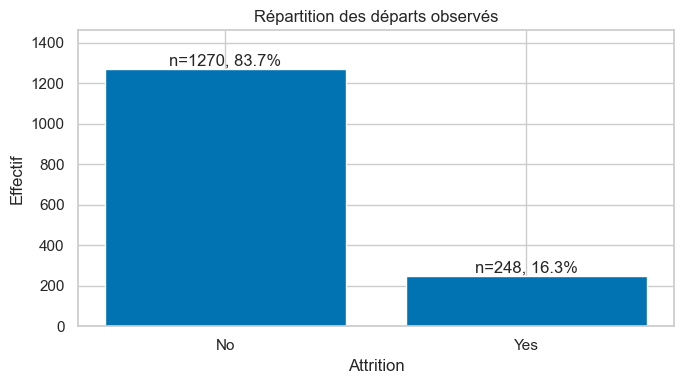

Proportion globale de départ : 16.3% (248/1518)


In [5]:
repartition = df.Attrition.value_counts().rename_axis("Attrition").reset_index(name="effectif")
repartition["part"] = repartition.effectif / len(df)
display(export_table(repartition, "01_attrition"))
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(repartition.Attrition, repartition.effectif)
for i, row in repartition.iterrows():
    ax.text(i, row.effectif, f"n={row.effectif}, {row.part:.1%}", ha="center", va="bottom")
ax.set(xlabel="Attrition", ylabel="Effectif", title="Répartition des départs observés", ylim=(0, repartition.effectif.max()*1.15))
save_figure(fig, "01_attrition")
print(f"Proportion globale de départ : {df.depart.mean():.1%} ({df.depart.sum()}/{len(df)})")

## Limites de mesure
Aucune colonne ne mesure les jours d’absence, les épisodes d’absence ou le temps de présence : l’absentéisme n’est pas mesurable. `StandardHours`, constant, ne mesure pas les heures réellement travaillées. Les modalités inhabituelles des scores sont conservées faute de dictionnaire. Aucun pays, date de départ ou établissement n’est disponible : la transposition à l’expansion africaine devra être validée localement.